<a href="https://colab.research.google.com/github/mcasasarrojo/EEG-Signal-Quality-Pipeline/blob/main/eeg_signal_quality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EEG Signal Quality Pipeline

Automated quality check for EEG recordings, built with MNE-Python.

What this notebook does:
1. Loads public EEG data (PhysioNet EEG Motor Movement/Imagery Dataset): resting state with eyes open and eyes closed.
2. Preprocesses the signal (band-pass and notch filtering).
3. Scores the quality of every channel (flat channels, noisy channels, line noise) and detects eye blinks.
4. Checks a known physiological effect: alpha power (8-13 Hz) rises when the eyes close.
5. Generates an HTML quality report for each recording.
6. Bonus: a simple classifier that tells eyes open from eyes closed using band powers.

Author: María Casás Arrojo

## 0. Setup
Run this once. In Google Colab it takes about a minute.

In [5]:
!pip install -q mne scikit-learn

In [6]:
import os
import base64
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from mne.datasets import eegbci
from scipy.integrate import trapezoid
from scipy.signal import find_peaks
from scipy.stats import wilcoxon

mne.set_log_level('WARNING')  # less text in the output

## 1. Parameters

PhysioNet recorded this dataset in the USA, so the power line is at **60 Hz** (in Europe it would be 50 Hz).

Runs used:
- Run 1: resting, eyes open (1 minute)
- Run 2: resting, eyes closed (1 minute)

In [7]:
SUBJECTS = list(range(1, 11))  # first 10 subjects
RUNS = {1: 'eyes_open', 2: 'eyes_closed'}

LINE_FREQ = 60  # power line frequency (USA)
L_FREQ, H_FREQ = 1.0, 40.0  # band-pass limits in Hz

FRONTAL = ['Fp1', 'Fp2']  # channels where blinks show up
OCCIPITAL = ['O1', 'Oz', 'O2']  # channels where alpha is strongest

BANDS = {'delta': (1, 4), 'theta': (4, 8), 'alpha': (8, 13), 'beta': (13, 30)}

REPORT_DIR = 'reports'
os.makedirs(REPORT_DIR, exist_ok=True)

## 2. Load the data

In [4]:
def load_run(subject, run):
    files = eegbci.load_data(subject, [run], update_path=True)  # downloads the EDF file
    raw = mne.io.read_raw_edf(files[0], preload=True)
    eegbci.standardize(raw)  # fixes channel names (e.g. 'Fp1.' -> 'Fp1')
    raw.set_montage('standard_1005')  # electrode positions
    return raw

raw = load_run(1, 2)
print(raw)
print('Sampling rate:', raw.info['sfreq'], 'Hz')
print('Channels:', len(raw.ch_names))

<RawEDF | S001R02.edf, 64 x 9760 (61.0 s), ~4.8 MiB, data loaded>
Sampling rate: 160.0 Hz
Channels: 64


/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions


Quick look at the raw signal before any filtering:

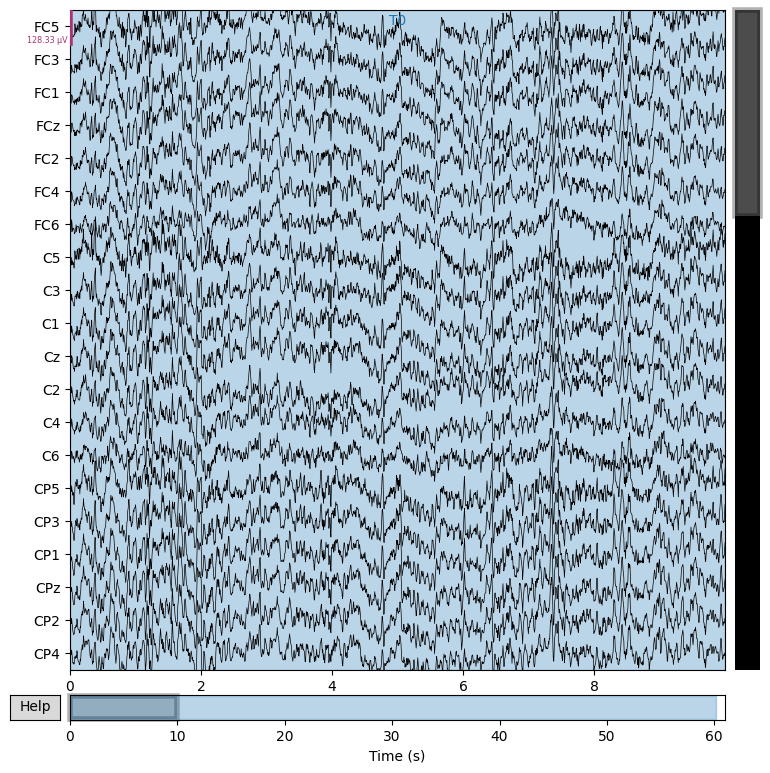

In [8]:
raw.plot(duration=10, n_channels=20, scalings='auto', show=True);

## 3. Preprocessing

- **Band-pass 1-40 Hz**: removes slow drifts (below 1 Hz) and high-frequency noise (above 40 Hz).
- **Notch at 60 Hz**: removes power line interference.

The notch is applied first, on the raw signal, so we can measure how much line noise there was.

/tmp/ipykernel_786/2429986653.py:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


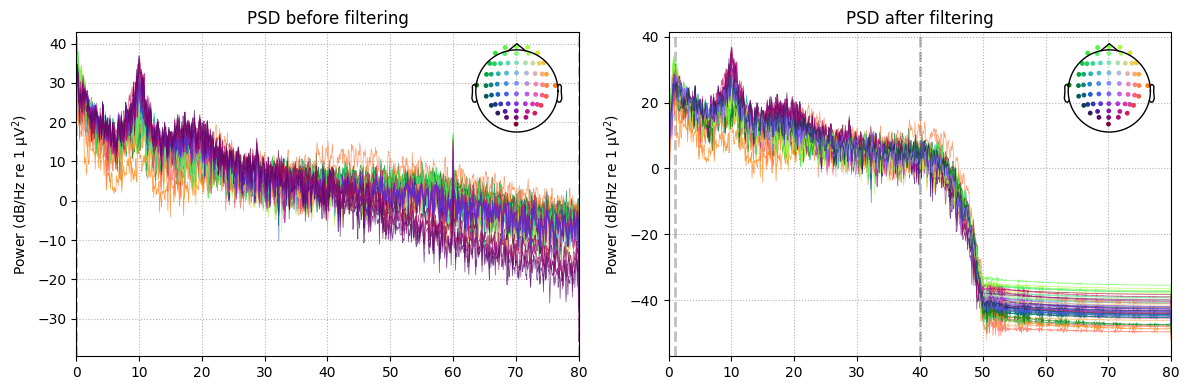

In [9]:
def preprocess(raw):
    clean = raw.copy()
    clean.notch_filter(LINE_FREQ)  # removes power line noise
    clean.filter(L_FREQ, H_FREQ)  # band-pass
    return clean

clean = preprocess(raw)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw.compute_psd(fmax=80).plot(axes=axes[0], show=False)
axes[0].set_title('PSD before filtering')
clean.compute_psd(fmax=80).plot(axes=axes[1], show=False)
axes[1].set_title('PSD after filtering')
plt.tight_layout()
plt.show()

## 4. Channel quality

For every channel we compute:
- **Peak-to-peak amplitude**: a flat channel (almost zero) usually means a disconnected electrode.
- **Robust z-score of high-frequency noise**: standard deviation of the 20-40 Hz band (muscle and electrode noise), compared with the rest of the channels. We use only this band so that blinks and alpha waves, which are low frequency and real brain or eye activity, do not count as noise.
- **Line noise z-score**: power around 60 Hz on the raw signal, compared with the other channels. Some line noise is normal (the notch filter removes it), but a channel with much more than the rest usually has bad electrode contact.

Each channel gets a status: OK, NOISY or FLAT.

In [10]:
FLAT_UV = 1.0  # peak-to-peak below this (in µV) = flat
NOISY_Z = 3.5  # robust z-score above this = noisy

def robust_z(x):
    med = np.median(x)
    mad = max(np.median(np.abs(x - med)) * 1.4826, 0.1)  # robust spread, with a floor
    return (x - med) / mad

def channel_quality(raw, clean):
    data = clean.get_data() * 1e6  # volts -> µV
    ptp = np.ptp(data, axis=1)

    hf = clean.copy().filter(20, 40).get_data() * 1e6  # high-frequency noise only
    z = robust_z(np.log(hf.std(axis=1) + 1e-12))

    psd = raw.compute_psd(fmin=1, fmax=70)
    freqs = psd.freqs
    p = psd.get_data()
    line = p[:, (freqs > LINE_FREQ - 2) & (freqs < LINE_FREQ + 2)].sum(axis=1)
    band = p[:, (freqs >= L_FREQ) & (freqs <= H_FREQ)].sum(axis=1)
    line_ratio = line / band
    line_z = robust_z(np.log(line + 1e-30))

    status = np.where(ptp < FLAT_UV, 'FLAT',
             np.where((z > NOISY_Z) | (line_z > NOISY_Z), 'NOISY', 'OK'))

    return pd.DataFrame({'channel': clean.ch_names, 'ptp_uV': ptp.round(1),
                         'noise_z': z.round(2), 'line_ratio': line_ratio.round(3),
                         'line_z': line_z.round(2), 'status': status})

quality = channel_quality(raw, clean)
print(quality['status'].value_counts())
quality.sort_values('noise_z', ascending=False).head(10)

status
OK       63
NOISY     1
Name: count, dtype: int64


,channel,ptp_uV,noise_z,line_ratio,line_z,status
62,O2,533.8,3.90,0.000,-4.96,NOISY
60,O1,568.2,3.24,0.000,-6.90,OK
41,T8,247.7,3.15,0.022,3.18,OK
61,Oz,521.6,3.09,0.000,-5.57,OK
63,Iz,466.1,3.08,0.000,-3.80,OK
59,PO8,546.1,2.69,0.002,1.21,OK
55,PO7,548.4,1.92,0.001,-0.47,OK
58,PO4,450.1,1.81,0.002,0.35,OK
56,PO3,530.9,1.65,0.001,-0.44,OK
57,POz,487.4,1.37,0.002,0.13,OK


## 5. Blink detection

Eye blinks are the most common EEG artifact. They appear as large, slow waves on the frontal channels (Fp1, Fp2).

Method: low-pass the frontal signal at 10 Hz, then find positive peaks above an adaptive threshold (median + k · MAD), the same idea used for MVC detection in my EMG project.

0 blinks in 61 s (0.0 per minute)


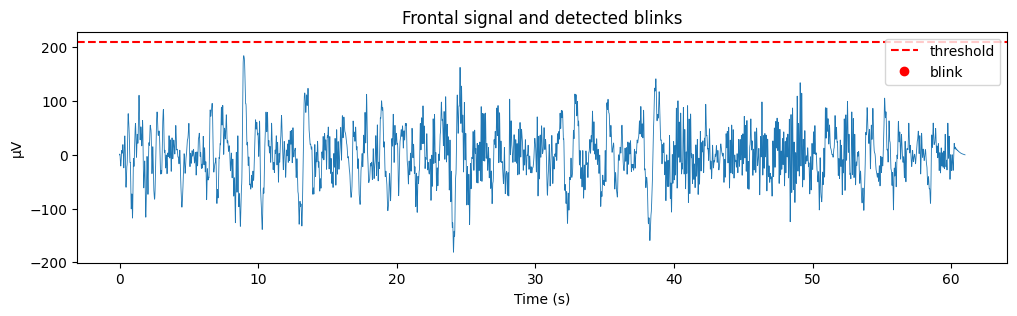

In [11]:
BLINK_K = 5  # threshold = median + k * MAD
MIN_GAP_S = 0.3  # minimum time between two blinks

def detect_blinks(clean):
    frontal = [ch for ch in FRONTAL if ch in clean.ch_names]
    sig = clean.copy().pick(frontal).filter(None, 10).get_data().mean(axis=0) * 1e6
    sig = sig - np.median(sig)

    mad = np.median(np.abs(sig)) * 1.4826
    thr = BLINK_K * mad

    peaks, _ = find_peaks(sig, height=thr, distance=int(MIN_GAP_S * clean.info['sfreq']))  # blinks are positive peaks at Fp1/Fp2
    times = peaks / clean.info['sfreq']
    return sig, thr, times

sig, thr, blink_times = detect_blinks(clean)
duration = clean.times[-1]
print(f'{len(blink_times)} blinks in {duration:.0f} s ({len(blink_times) / duration * 60:.1f} per minute)')

t = clean.times
plt.figure(figsize=(12, 3))
plt.plot(t, sig, lw=0.6)
plt.axhline(thr, color='r', ls='--', label='threshold')
plt.plot(blink_times, sig[(blink_times * clean.info['sfreq']).astype(int)], 'ro', label='blink')
plt.xlabel('Time (s)')
plt.ylabel('µV')
plt.title('Frontal signal and detected blinks')
plt.legend()
plt.show()

## 6. Overall quality score

A single number from 0 to 100 for the whole recording:
- starts at 100
- minus 3 points per bad channel (noisy or flat)
- minus 0.5 points per blink per minute above 20 (normal blink rate is around 15-20 per minute)

In [12]:
def quality_score(quality, n_blinks, duration_s):
    bad = (quality['status'] != 'OK').sum()
    blinks_per_min = n_blinks / duration_s * 60
    score = 100 - 3 * bad - 0.5 * max(0, blinks_per_min - 20)
    return max(0, round(score, 1)), int(bad), round(blinks_per_min, 1)

score, n_bad, bpm = quality_score(quality, len(blink_times), duration)
print('Score:', score, '| bad channels:', n_bad, '| blinks/min:', bpm)

Score: 97.0 | bad channels: 1 | blinks/min: 0.0


## 7. Physiological check: alpha power with eyes open vs closed

When we close our eyes, alpha activity (8-13 Hz) over the occipital cortex increases clearly. This is the classic Berger effect. If the pipeline works, we should see it in almost every subject.

/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions
/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions


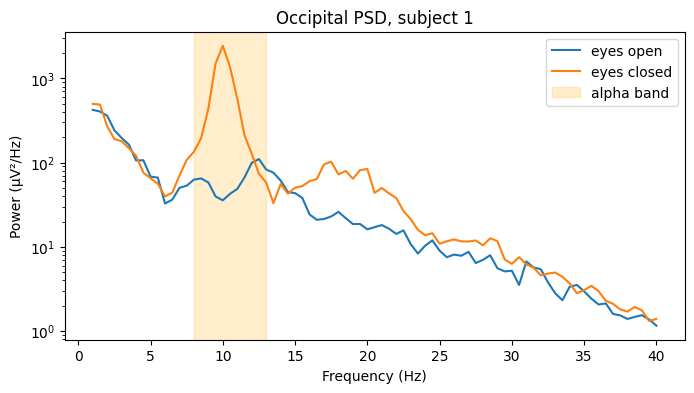

Alpha eyes open: 271.2 µV² | eyes closed: 3481.7 µV² | ratio: 12.84


In [13]:
def band_power(clean, picks, fmin, fmax):
    psd = clean.compute_psd(method='welch', fmin=1, fmax=40, picks=picks, n_fft=int(2 * clean.info['sfreq']))
    freqs = psd.freqs
    p = psd.get_data().mean(axis=0)  # average over channels
    mask = (freqs >= fmin) & (freqs < fmax)
    return trapezoid(p[mask], freqs[mask]) * 1e12  # V² -> µV²

raw_open = preprocess(load_run(1, 1))
raw_closed = preprocess(load_run(1, 2))

fig, ax = plt.subplots(figsize=(8, 4))
for r, label in [(raw_open, 'eyes open'), (raw_closed, 'eyes closed')]:
    psd = r.compute_psd(fmin=1, fmax=40, picks=OCCIPITAL, n_fft=int(2 * r.info['sfreq']))
    ax.semilogy(psd.freqs, psd.get_data().mean(axis=0) * 1e12, label=label)
ax.axvspan(8, 13, color='orange', alpha=0.2, label='alpha band')
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Power (µV²/Hz)')
ax.set_title('Occipital PSD, subject 1')
ax.legend()
plt.show()

a_open = band_power(raw_open, OCCIPITAL, 8, 13)
a_closed = band_power(raw_closed, OCCIPITAL, 8, 13)
print(f'Alpha eyes open: {a_open:.1f} µV² | eyes closed: {a_closed:.1f} µV² | ratio: {a_closed / a_open:.2f}')

Now for all subjects:

/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions
/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions
/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions
/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions
/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' in

   subject  alpha_open  alpha_closed  ratio
0        1       271.2        3481.7  12.84
1        2       116.4        1133.7   9.74
2        3       176.6        3023.5  17.12
3        4        17.5         462.0  26.34
4        5        24.6          33.2   1.35
5        6        16.5          19.3   1.17
6        7       518.7        1663.8   3.21
7        8        40.3         269.9   6.69
8        9        82.0         313.7   3.83
9       10       159.1        1906.6  11.98
Alpha increased with eyes closed in 10 of 10 subjects
Wilcoxon signed-rank test: p = 0.0020


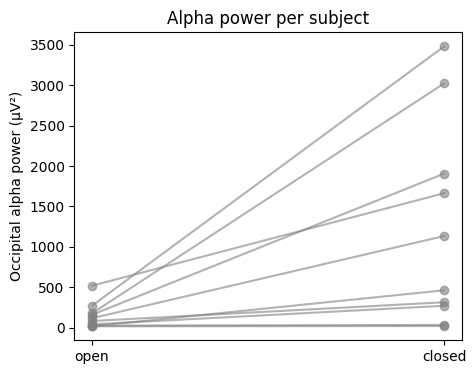

In [14]:
rows = []
for s in SUBJECTS:
    a_o = band_power(preprocess(load_run(s, 1)), OCCIPITAL, 8, 13)
    a_c = band_power(preprocess(load_run(s, 2)), OCCIPITAL, 8, 13)
    rows.append({'subject': s, 'alpha_open': round(a_o, 1), 'alpha_closed': round(a_c, 1),
                 'ratio': round(a_c / a_o, 2)})

alpha_df = pd.DataFrame(rows)
print(alpha_df)
print(f"Alpha increased with eyes closed in {(alpha_df['ratio'] > 1).sum()} of {len(alpha_df)} subjects")

stat, pval = wilcoxon(alpha_df['alpha_closed'], alpha_df['alpha_open'])
print(f'Wilcoxon signed-rank test: p = {pval:.4f}')

plt.figure(figsize=(5, 4))
for _, r in alpha_df.iterrows():
    plt.plot(['open', 'closed'], [r['alpha_open'], r['alpha_closed']], 'o-', color='gray', alpha=0.6)
plt.ylabel('Occipital alpha power (µV²)')
plt.title('Alpha power per subject')
plt.show()

## 8. HTML quality report

One report per recording, with the score, the channel table, the blink plot and the topographic map of channel noise. This is the kind of file a researcher could check before using a recording in a study.

In [15]:
def fig_to_base64(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=100, bbox_inches='tight')
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode()

def make_report(subject, run):
    raw = load_run(subject, run)
    clean = preprocess(raw)
    q = channel_quality(raw, clean)
    sig, thr, blinks = detect_blinks(clean)
    dur = clean.times[-1]
    score, n_bad, bpm = quality_score(q, len(blinks), dur)

    fig1, ax = plt.subplots(figsize=(10, 2.5))  # blink plot
    ax.plot(clean.times, sig, lw=0.5)
    ax.axhline(thr, color='r', ls='--')
    ax.plot(blinks, sig[(blinks * clean.info['sfreq']).astype(int)], 'ro')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('µV')
    ax.set_title('Frontal signal and blinks')

    fig2, ax2 = plt.subplots(figsize=(4, 4))  # topomap of noise
    mne.viz.plot_topomap(np.clip(q['noise_z'].values, -5, 5), clean.info, axes=ax2, show=False, cmap='RdYlGn_r', vlim=(-5, 5))  # clipped so one extreme channel does not hide the rest
    ax2.set_title('Channel noise (robust z)')

    bad_rows = q[q['status'] != 'OK']
    table = bad_rows.to_html(index=False) if len(bad_rows) else '<p>All channels OK.</p>'
    color = '#2e7d32' if score >= 80 else '#f9a825' if score >= 60 else '#c62828'

    html = f'''<html><head><meta charset="utf-8"><title>EEG quality S{subject:03d} R{run:02d}</title>
    <style>body{{font-family:Arial;max-width:900px;margin:30px auto}} table{{border-collapse:collapse}}
    td,th{{border:1px solid #ccc;padding:4px 8px}}</style></head><body>
    <h1>EEG quality report</h1>
    <p>Subject {subject} · run {run} ({RUNS[run]}) · {dur:.0f} s · {len(clean.ch_names)} channels</p>
    <h2 style="color:{color}">Quality score: {score} / 100</h2>
    <ul><li>Bad channels: {n_bad}</li><li>Blinks per minute: {bpm}</li></ul>
    <h3>Channels flagged</h3>{table}
    <h3>Blinks</h3><img src="data:image/png;base64,{fig_to_base64(fig1)}">
    <h3>Noise map</h3><img src="data:image/png;base64,{fig_to_base64(fig2)}">
    </body></html>'''

    path = f'{REPORT_DIR}/S{subject:03d}_R{run:02d}_quality.html'
    with open(path, 'w') as f:
        f.write(html)
    return {'subject': subject, 'run': RUNS[run], 'score': score, 'bad_channels': n_bad, 'blinks_per_min': bpm}

summary = pd.DataFrame([make_report(s, r) for s in SUBJECTS for r in RUNS])
summary.to_csv(f'{REPORT_DIR}/summary.csv', index=False)
summary

/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions
/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions
/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions
/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions
/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' in

,subject,run,score,bad_channels,blinks_per_min
0,1,eyes_open,97.0,1,11.8
1,1,eyes_closed,97.0,1,0.0
2,2,eyes_open,93.2,2,21.6
3,2,eyes_closed,79.0,7,2.0
4,3,eyes_open,93.2,2,21.6
5,3,eyes_closed,94.0,2,1.0
6,4,eyes_open,91.0,3,6.9
7,4,eyes_closed,100.0,0,0.0
8,5,eyes_open,94.0,2,15.7
9,5,eyes_closed,94.0,2,0.0


To open a report in Colab:

channel,ptp_uV,noise_z,line_ratio,line_z,status
O2,533.8,3.9,0.0,-4.96,NOISY

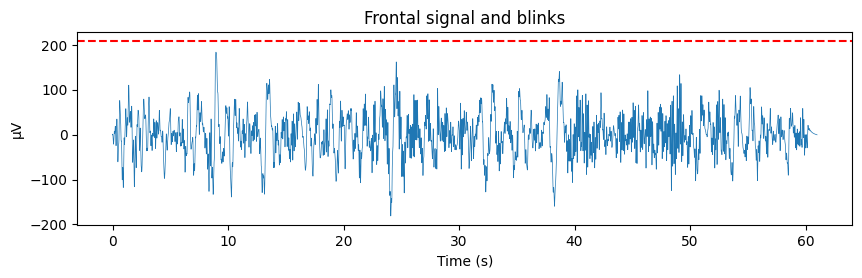
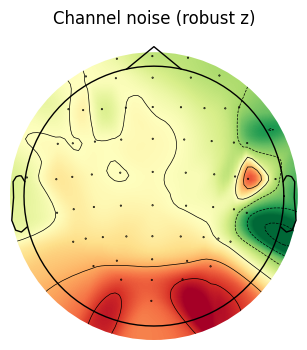

In [16]:
from IPython.display import HTML
HTML(open(f'{REPORT_DIR}/S001_R02_quality.html').read())

## 9. Bonus: eyes open vs eyes closed classifier

Each recording is cut into 2-second windows. For each window we compute the power in the four bands on the occipital channels. Then a logistic regression tries to guess whether the eyes were open or closed.

Cross-validation is done **by subject** (GroupKFold): the model is always tested on people it has never seen.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_score

def window_features(clean, win_s=2.0):
    epochs = mne.make_fixed_length_epochs(clean, duration=win_s, preload=True)
    psd = epochs.compute_psd(fmin=1, fmax=40, picks=OCCIPITAL)
    freqs = psd.freqs
    p = psd.get_data().mean(axis=1)  # average over channels -> (n_windows, n_freqs)
    feats = [np.log(p[:, (freqs >= lo) & (freqs < hi)].mean(axis=1)) for lo, hi in BANDS.values()]
    return np.column_stack(feats)

X, y, groups = [], [], []
for s in SUBJECTS:
    for run, label in [(1, 0), (2, 1)]:  # 0 = open, 1 = closed
        f = window_features(preprocess(load_run(s, run)))
        X.append(f)
        y += [label] * len(f)
        groups += [s] * len(f)
X = np.vstack(X)
y = np.array(y)

model = make_pipeline(StandardScaler(), LogisticRegression())
scores = cross_val_score(model, X, y, groups=groups, cv=GroupKFold(n_splits=5))
print(f'Accuracy on unseen subjects: {scores.mean():.2f} ± {scores.std():.2f}')

model.fit(X, y)
coefs = pd.Series(model[-1].coef_[0], index=BANDS.keys())
print('Feature weights (positive = eyes closed):')
print(coefs.round(2))

/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions
/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions
/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions
/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')  # electrode positions
/tmp/ipykernel_786/3955218461.py:5: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' in

Accuracy on unseen subjects: 0.76 ± 0.10
Feature weights (positive = eyes closed):
delta   -1.02
theta   -0.10
alpha    2.23
beta    -0.37
dtype: float64


## 10. Conclusions

- The pipeline flags flat and noisy channels and detects blinks automatically, and summarises each recording in a single quality score and an HTML report.
- The alpha check works as a sanity test: alpha power rises with eyes closed, as expected physiologically.
- A simple model based only on band powers can tell eyes open from eyes closed in subjects it has never seen.

Possible next steps: ICA to remove blinks instead of just detecting them, and a sliding-window alpha index (the basis of alpha neurofeedback).